Goal : Look at some extinction curves from the literature, use one of those curves to deredden an 
observed spectrum, and practice invoking a background source flux in order to calculate magnitudes from an extinction model

In [1]:
# Primary libraries being used :
#1. synphot
#2. dust_extinction

!pip install synphot
!pip install dust_extinction


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 917.4/917.4 kB 5.3 MB/s  0:00:00 eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 2.0 MB/s  0:00:02m0:00:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for dust_extinction: filename=dust_extinction-1.7-py3-none-any.whl size=3459927 sha256=5e06b39eb6a99ad01605992b4ab5bdf2ef49962311eeb45a62c692354649ec47
  Stored in directory: /home/user/.cache/pip/wheels/f7/60/9e/0f8371b9f474f8147820ee0d75ba007ed19884b27cc136e1f8
Successfully built dust_extinction


In [3]:
import pathlib

import matplotlib.pyplot as plt

%matplotlib inline

import numpy as np
import astropy.units as u
from astropy.table import Table

from dust_extinction.parameter_averages import CCM89, F99

from synphot import units, config
from synphot import SourceSpectrum, SpectralElement, Observation, ReddeningLaw

from synphot.models import BlackBodyNorm1D
from astroquery.simbad import Simbad
from astroquery.mast import Observations
import astropy.visualization


Dust in the interstellar medium (ISM) extinguishes background starlight. The wavelength dependence of the extinction is such that short-wavelength light is extinguished more than long-wavelength light, and we call this effect reddening.

The dust_extinction model provides various models for extinction. A_(lambda) normalized to A_(V). The shapes of normalized curves are relatively(and perhaps surprisingly) uniform in the Milky way. The little Variation that exists is often parameterized by the ratio of extinction(A_v) to reddening in the blue-visual(E_(B-V)).

E_(B-V) is differential extinction (A_(B)-A(V)). 

This tutorial is focused on R_(V) parameterization for the Clayton, Cardelli & Mathis(1989,CCM) and Fitzpatrick(1999) models.

#Investigate Extinction Models

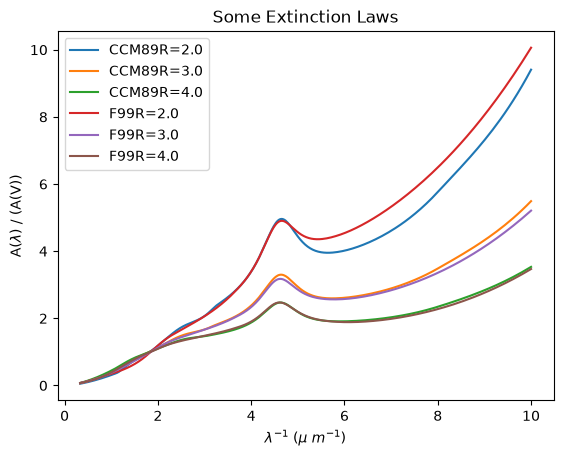

In [9]:

 #Create wavelength array

wav= np.arange(0.1, 3.0, 0.001) * u.micron

for model in [CCM89, F99]:
    for R in(2.0, 3.0, 4.0 ):
        extinction = model(Rv=R) # Initialize model extinction
        plt.plot(1/ wav, extinction(wav), label=model.name + "R=" + str(R))

plt.xlabel(r"$ \lambda^{-1} $ ($ \mu$ $ m^{-1}$)")
plt.ylabel(r"A($ \lambda$) / (A(V))")
plt.legend(loc="best")
plt.title("Some Extinction Laws")
plt.show()



Here we studied ISM, and saw graph extinction curves against inverse wavelength(wave number) to show the ultravoilet variation.

 Infrared extinction varies much less and approaches zero at long wavelength in the absence of wavelength-independent or grey, extinction.  

Here We are going to use astroquery to fetch the archival (International Ultravoilet Explorer(IUE))spectrum from MAST( Mikulski Archive for Space Telescopes).

In [ ]:
# Deredden a spectrum
# Here we deredden (unextinguish) the IUE ultravoilet spectrum and 
# optical photometry of the star Oph(HD 147933)



In [ ]:
download_dir = pathlib.Path("~/.astropy/cache/astroquery/Mast").expanduser()
download_dir.mkdir(exist_ok=True, parents=True)

obsTable= Observations.query_object("HD 147933", radius="1 arcsec")
obsTable_spec = obsTable[obsTable["dataproduct_type"]=="spectrum"]
obsTable_spec


intentType,obs_collection,provenance_name,instrument_name,project,filters,wave_region,target_name,target_classification,obs_id,s_ra,s_dec,dataproduct_type,proposal_pi,calib_level,t_min,t_max,t_exptime,wavelength_region,em_min,em_max,obs_title,t_obs_release,proposal_id,proposal_type,sequence_number,s_region,jpegURL,dataURL,dataRights,mtFlag,srcDen,obsid,wave_min,wave_max,distance
str7,str5,str7,str13,str6,str17,str16,str21,str87,str53,float64,float64,str10,str22,int64,float64,float64,float64,str16,float64,float64,str117,float64,str6,str6,int64,str23309,str137,str137,str6,bool,float64,str9,float64,float64,float64
science,JWST,APT,MIRI/IFU,JWST,F770W,INFRARED,HD147933,--,jw07715021001_xx101_00001_miri,246.39632750000004,-23.447175000000016,spectrum,"Decleir, Marjorie",-1,nan,nan,16.65,INFRARED,6600.0,8800.0,Unique insights into the chemical composition of interstellar silicate dust grains in the Milky Way,nan,7715,GO,1,POLYGON 246.39628332931 -23.44647682166 246.39724452752 -23.44660740232 246.39707945891 -23.44762998653 246.39611825342 -23.44749937708,--,--,PUBLIC,False,nan,250358393,6600.0,8800.0,0.0
science,JWST,APT,MIRI/IFU,JWST,F770W,INFRARED,HD147933,--,jw07715021001_xx102_00002_miri,246.39632750000004,-23.447175000000016,spectrum,"Decleir, Marjorie",-1,nan,nan,16.65,INFRARED,6600.0,8800.0,Unique insights into the chemical composition of interstellar silicate dust grains in the Milky Way,nan,7715,GO,2,POLYGON 246.39564102259 -23.44666562072 246.39660222154 -23.44679620531 246.39643714773 -23.44781878885 246.39547594149 -23.44768817546,--,--,PUBLIC,False,nan,250358394,6600.0,8800.0,0.0
science,JWST,APT,MIRI/IFU,JWST,F770W,INFRARED,HD147933,--,jw07715021001_xx103_00003_miri,246.39632750000004,-23.447175000000016,spectrum,"Decleir, Marjorie",-1,nan,nan,16.65,INFRARED,6600.0,8800.0,Unique insights into the chemical composition of interstellar silicate dust grains in the Milky Way,nan,7715,GO,3,POLYGON 246.39618623396 -23.44653838938 246.39714743253 -23.44666897063 246.39698236309 -23.44769155474 246.39602115724 -23.4475609447,--,--,PUBLIC,False,nan,250358395,6600.0,8800.0,0.0
science,JWST,APT,MIRI/IFU,JWST,F770W,INFRARED,HD147933,--,jw07715021001_xx104_00004_miri,246.39632750000004,-23.447175000000016,spectrum,"Decleir, Marjorie",-1,nan,nan,16.65,INFRARED,6600.0,8800.0,Unique insights into the chemical composition of interstellar silicate dust grains in the Milky Way,nan,7715,GO,4,POLYGON 246.39554415903 -23.44672814693 246.39650535835 -23.44685873212 246.3963402837 -23.44788131555 246.3953790771 -23.44775070157,--,--,PUBLIC,False,nan,250358396,6600.0,8800.0,0.0
science,JWST,APT,MIRI/IFU,JWST,F1000W,INFRARED,HD147933,--,jw07715021001_xx105_00001_miri,246.39632750000004,-23.447175000000016,spectrum,"Decleir, Marjorie",-1,nan,nan,19.425,INFRARED,9000.0,11000.0,Unique insights into the chemical composition of interstellar silicate dust grains in the Milky Way,nan,7715,GO,5,POLYGON 246.39628332931 -23.44647682166 246.39724452752 -23.44660740232 246.39707945891 -23.44762998653 246.39611825342 -23.44749937708,--,--,PUBLIC,False,nan,250358397,9000.0,11000.0,0.0
science,JWST,APT,MIRI/IFU,JWST,F1000W,INFRARED,HD147933,--,jw07715021001_xx106_00002_miri,246.39632750000004,-23.447175000000016,spectrum,"Decleir, Marjorie",-1,nan,nan,19.425,INFRARED,9000.0,11000.0,Unique insights into the chemical composition of interstellar silicate dust grains in the Milky Way,nan,7715,GO,6,POLYGON 246.39564102259 -23.44666562072 246.39660222154 -23.44679620531 246.39643714773 -23.44781878885 246.39547594149 -23.44768817546,--,--,PUBLIC,False,nan,250358398,9000.0,11000.0,0.0
science,JWST,APT,MIRI/IFU,JWST,F1000W,INFRARED,HD147933,--,jw07715021001_xx107_00003_miri,246.39632750000004,-23.447175000000016,spectrum,"Decleir, Marjorie",-1,nan,nan,19.425,INFRARED,9000.0,11000.0,Unique insights into the chemical composition of interstellar silicate dust grains in the Milky Way,nan,7715,GO,7,POLYGON 246.39618623396 -23.44653838938 246.39714743253 -23.44666897063 24

In [24]:
A= obsTable_spec.colnames
print(A)

['intentType', 'obs_collection', 'provenance_name', 'instrument_name', 'project', 'filters', 'wave_region', 'target_name', 'target_classification', 'obs_id', 's_ra', 's_dec', 'dataproduct_type', 'proposal_pi', 'calib_level', 't_min', 't_max', 't_exptime', 'wavelength_region', 'em_min', 'em_max', 'obs_title', 't_obs_release', 'proposal_id', 'proposal_type', 'sequence_number', 's_region', 'jpegURL', 'dataURL', 'dataRights', 'mtFlag', 'srcDen', 'obsid', 'wave_min', 'wave_max', 'distance']


In [11]:
# retrieving a specific "obs_id" corresponding to IUE Spectrum

obsTable_spec.add_index("obs_id")
obsids = obsTable_spec.loc["lwr05639"]["obsid"]

dataProductsByID = Observations.get_product_list(obsids)
manifest = Observations.download_products(
    dataProductByID, download_dir=str(download_dir)
    
)

KeyboardInterrupt: 

In [13]:
t_lwr = Table.read(download_dir /"mastDownload/IUE/lwt05539/lwr05639mxlo_vo.fits"
                   )
print(t_lwr)

FileNotFoundError: [Errno 2] No such file or directory: '/home/user/.astropy/cache/astroquery/Mast/mastDownload/IUE/lwt05539/lwr05639mxlo_vo.fits'

.quantity extension reads the Table columns into Quantity vectors. 

In [ ]:
wav_UV = t_lwr["WAVE"][0,].quantity
UVflux = t_lwr["Flux"][0,].quantity
